# Explicaciones que se mantienen: semillas, códigos de razón, aditividad de Shapley, dependencia parcial y efectos locales acumulados

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- medir cuánto se mueven el AUC de un modelo, los grados que asigna y el orden de sus atribuciones cuando cambia solo la semilla de entrenamiento, y leer cada uno contra su convención;
- explicar qué es un código de razón (una contribución con signo hacia el incumplimiento), medir qué tan estables son los cuatro primeros entre reajustes y decir por qué importa el signo;
- comprobar que las atribuciones de Shapley suman la predicción, y ver fallar la comprobación cuando no suman;
- calcular la dependencia parcial, la expectativa condicional individual (ICE) y los efectos locales acumulados (ALE) de un modelo dado como función, comprobar sus identidades, y comparar dos explicadores por concordancia de rangos y por el signo y la monotonía de un efecto;
- leer el barrido de semillas versionado del caso C20 y reconstruir sus filas con el motor.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ml import effects, explanations, plants, seeds
from riskvalidation.ml.explanations import OverlapResult
from riskvalidation.ml.seeds import SeedDispersion
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import ml as vml
from scipy import special

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

- **La planta inestable por semilla** del motor (`SeedUnstablePlant`): incumplidores y sobrevivientes separados por una columna de señal, una columna de puro ruido, y un modelo cuyo peso sobre la columna de ruido cambia con la semilla de entrenamiento en una cantidad que elegimos (`instability`). La media y la dispersión del AUC entre semillas se conocen por cuadratura, así que la prueba puede contrastarse con la verdad.
- **Una familia de modelos logit lineales** escrita en este cuaderno: ocho variables, un vector de coeficientes base y un vector por semilla o reajuste que se mueve alrededor de la base en una cantidad elegida. Para un modelo lineal sobre la log-odds el valor de Shapley de la variable $j$ tiene forma cerrada, $\phi_{ij} = \beta_j (x_{ij} - \bar{x}_j)$ (Lundberg y Lee, 2017, para variables independientes), de modo que las atribuciones son exactas y las revisiones del motor pueden leerse contra una respuesta conocida. Son datos para las funciones del motor; el cuaderno no implementa ninguna de ellas.
- **El barrido de semillas versionado del caso C20** (`data/derived/C20/seed-sweep.json`; propietario: este repositorio, derivado de los datos de tarjetas de Taiwán de UCI, CC BY 4.0, clase mirror-allowed): un modelo LightGBM y uno XGBoost reajustados con 20 semillas, 100 reajustes bootstrap para los códigos de razón y una curva ALE para cada variable principal. El pipeline calculó las atribuciones TreeSHAP con el `shap` fijado y entregó arreglos al motor; el motor nunca importa `shap` ni los aprendices. La celda siguiente abre el documento.

In [2]:
# Abrir el barrido de semillas versionado e imprimir el motor que lo horneó y sus filas
sweep = json.loads((ROOT / "data" / "derived" / "C20" / "seed-sweep.json").read_text(encoding="utf-8"))
print("horneado con riskvalidation", sweep["provenance"]["riskvalidation_version"], "| filas de prueba", len(sweep["tests"]))
for row in sweep["outputs"]["rows"]:
    print(f'{row["rung"]:14s} semillas {row["n_seeds"]} | AUC media {row["auc"]["mean"]:.4f} desv {row["auc"]["sd"]:.5f} | proporción de deudores cuyo grado cambia {row["grade_assignment_changed_share"]:.4f}')

horneado con riskvalidation 0.8.1 | filas de prueba 22
P4-lightgbm    semillas 20 | AUC media 0.7774 desv 0.00105 | proporción de deudores cuyo grado cambia 0.6221
P4-xgboost     semillas 20 | AUC media 0.7761 desv 0.00079 | proporción de deudores cuyo grado cambia 0.5672


## Método

La guía del BCE pide al validador revisar la aleatoriedad del proceso de entrenamiento, la estabilidad de las explicaciones y la concordancia de los explicadores (párrafos 43, 59, 62, 64 a 66; ver las referencias). El motor convierte cada una en un número y, cuando puede, en una luz. Todos los puntos de corte son convenciones.

### Paso 1: el AUC entre semillas de entrenamiento

Un modelo entrenado dos veces desde semillas distintas son dos modelos. La prueba reajusta el modelo con $S \ge 2$ semillas distintas, puntúa cada uno sobre las mismas filas e informa la media, el mínimo, el máximo y la **desviación estándar muestral** (ddof 1) del AUC:

$$\mathrm{sd}_{\mathrm{AUC}} = \sqrt{\frac{1}{S-1}\sum_{s=1}^{S}\bigl(\mathrm{AUC}_s - \overline{\mathrm{AUC}}\bigr)^2}.$$

La luz es verde bajo 0,01, ámbar desde 0,01 y roja desde 0,02 (cerca del error estándar de muestreo del AUC de una reserva de Taiwán). El motor recibe la función de entrenamiento como un invocable `train(seed) -> predict`, que entrega la planta. La celda siguiente corre 20 semillas sobre una planta con inestabilidad 0,6 y sobre la planta estable (inestabilidad 0), e imprime la dispersión del motor junto a la exacta.

In [3]:
# Dispersión del AUC en 20 semillas de entrenamiento sobre una planta inestable y una estable, contra los valores exactos
SEEDS = list(range(20))
dispersion = {}
for label, instability in (("inestable", 0.6), ("estable", 0.0)):
    plant = plants.SeedUnstablePlant(n=5000, instability=instability, seed=4)
    data = plant.sample()
    disp = seeds.seed_auc_dispersion(plant.train, data["X"], data["y"], SEEDS)
    exact = plant.truth()
    result = vml.seed_stability("planta-semillas", disp)
    dispersion[label] = (plant, data, disp)
    print(f"{label:11s} AUC media {disp.mean:.4f} (exacto {exact['mean_auc']:.4f}) | desv {disp.sd:.5f} (exacto {exact['sd_auc_across_seeds']:.5f}) | rango {disp.minimum:.4f} {disp.maximum:.4f} | luz {result.light.value}")

inestable   AUC media 0.8221 (exacto 0.8249) | desv 0.04564 (exacto 0.03354) | rango 0.7122 0.8618 | luz red
estable     AUC media 0.8618 (exacto 0.8556) | desv 0.00000 (exacto 0.00000) | rango 0.8618 0.8618 | luz green


La dispersión exacta es un valor poblacional; la medida viene de 20 semillas sobre una muestra de 5.000 filas, así que ambas coinciden solo en forma aproximada. Con la planta estable cada semilla da el mismo modelo y la dispersión es cero.

### Paso 2: el grado que recibe cada deudor

Un AUC que no se mueve puede esconder deudores que cambian de grado. Para $S$ semillas y PD $p_{si}$, con bordes de grado $e_1 < \dots < e_{g-1}$, el grado de una PD es el número de bordes iguales o menores que ella, y la proporción de deudores cuyo grado no es el mismo bajo todas las semillas es

$$\mathrm{cambia} = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\Bigl[\min_s \mathrm{grado}(p_{si}) \ne \max_s \mathrm{grado}(p_{si})\Bigr].$$

La función `grade_assignment_stability` del motor recibe un arreglo de forma $(S, n)$ y los bordes. La celda siguiente usa diez grados cortados en los deciles de la PD media entre semillas, para ambas plantas.

In [4]:
# Proporción de deudores cuyo grado cambia entre semillas, para la planta inestable y la estable
for label, (plant, data, disp) in dispersion.items():
    pd_by_seed = np.array([plant.train(s)(data["X"]) for s in SEEDS])
    edges = np.quantile(pd_by_seed.mean(axis=0), np.linspace(0, 1, 11)[1:-1])
    changed = seeds.grade_assignment_stability(pd_by_seed, edges)
    print(f"{label:11s} arreglo de PD {pd_by_seed.shape} | proporción cuyo grado cambia {changed:.4f}")

inestable   arreglo de PD (20, 5000) | proporción cuyo grado cambia 0.8918
estable     arreglo de PD (20, 5000) | proporción cuyo grado cambia 0.0000


### Paso 3: rangos de atribución y códigos de razón entre reajustes

La familia logit lineal tiene ocho variables y un vector de coeficientes base. Cada uno de 100 reajustes perturba los coeficientes con ruido gaussiano de desviación estándar 0,15, y la atribución del reajuste $r$ en la escala de log-odds es $\phi^{(r)}_{ij} = \beta^{(r)}_j (x_{ij} - \bar{x}_j)$. De ahí salen dos lecturas.

**El rango de la importancia global.** Para cada reajuste, la atribución absoluta media por variable da un ordenamiento; el motor informa la media y el mínimo de la $\tau_b$ de Kendall entre los ordenamientos de cada par de reajustes (1 es el mismo ordenamiento, con empates tratados).

**Los códigos de razón.** Las razones de un deudor en un reajuste son sus $k = 4$ **mayores contribuciones con signo hacia el incumplimiento**, en orden descendente (empates por orden de columna): una atribución negativa grande empuja hacia el pago y nunca es una razón para rechazar. Es la lectura con signo adoptada en el motor (las razones de acción adversa del comentario 9(b)(2)-5 de la Regulación B, donde la caída de Shapley hace el papel de la contribución del factor al puntaje). La proporción de las razones de un deudor que se mantienen entre los cuatro primeros del primer reajuste se promedia sobre los demás reajustes, y el motor informa la media y el percentil 5 entre deudores. Reajustes idénticos dan 1.

La celda siguiente construye los 100 reajustes sobre 1.000 deudores y llama a ambas funciones.

In [5]:
# Construir 100 reajustes logit lineales sobre 1.000 deudores con atribuciones de Shapley exactas y llamar a las dos funciones del motor
rng = np.random.default_rng(2026)
n_obligors, n_features, n_refits = 1000, 8, 100
features = rng.standard_normal((n_obligors, n_features))
base = np.array([1.2, -0.9, 0.7, 0.5, -0.4, 0.3, 0.2, -0.1])
betas = base + 0.15 * rng.standard_normal((n_refits, n_features))
centred = features - features.mean(axis=0)
attributions = betas[:, None, :] * centred[None, :, :]
importance = np.abs(attributions).mean(axis=1)
tau = seeds.attribution_rank_stability(importance)
signed = explanations.reason_code_overlap(attributions, top_k=4)
unsigned = explanations.reason_code_overlap(np.abs(attributions), top_k=4)
print("arreglo de atribuciones:", attributions.shape)
print(f"Kendall tau media {tau.mean_tau:.4f} | mínimo {tau.min_tau:.4f}")
print(f"códigos de razón, con signo hacia el incumplimiento: traslape medio {signed.mean:.4f} | p05 {signed.p05:.4f}")
print(f"las mismas atribuciones leídas por valor absoluto: traslape medio {unsigned.mean:.4f} | p05 {unsigned.p05:.4f}")
print("reajustes idénticos dan:", explanations.reason_code_overlap(np.repeat(attributions[:1], 5, axis=0), top_k=4).mean)

arreglo de atribuciones: (100, 1000, 8)
Kendall tau media 0.7108 | mínimo 0.2857
códigos de razón, con signo hacia el incumplimiento: traslape medio 0.8105 | p05 0.6766
las mismas atribuciones leídas por valor absoluto: traslape medio 0.8019 | p05 0.6413
reajustes idénticos dan: 1.0


Las lecturas con signo y absoluta dan traslapes distintos. En esta familia la diferencia es pequeña, pero la lectura absoluta puede contar como razón una variable que argumenta a favor del pago, y por eso la convención de signo es parte de la prueba y no un detalle. La luz del traslape con signo es verde sobre 0,80, ámbar en 0,80 o menos y roja en 0,60 o menos.

### Paso 4: aditividad de Shapley

Una explicación de Shapley exacta suma: $f(x_i) = \phi_0 + \sum_j \phi_{ij}$, donde $f$ es la salida del modelo en la escala de las atribuciones y $\phi_0$ el valor base (la salida media, aquí $\boldsymbol\beta\cdot\bar{x}$). El motor informa la **mayor brecha absoluta entre las filas**,

$$\mathrm{brecha} = \max_i \Bigl| f(x_i) - \bigl(\phi_0 + \textstyle\sum_j \phi_{ij}\bigr) \Bigr|,$$

y la luz es roja cuando la brecha supera la tolerancia numérica $10^{-9}$ y verde en otro caso. La celda siguiente comprueba las atribuciones del primer reajuste contra su log-odds y luego planta un defecto (una columna de atribuciones desplazada en $10^{-6}$) para ver activarse la prueba.

In [6]:
# Aditividad del primer reajuste, y luego con una columna de atribuciones desplazada en 1e-6
log_odds = features @ betas[0]
base_value = float(betas[0] @ features.mean(axis=0))
exact_gap = explanations.shapley_additivity_gap(log_odds, base_value, attributions[0])
broken = attributions[0].copy()
broken[:, 2] += 1e-6
broken_gap = explanations.shapley_additivity_gap(log_odds, base_value, broken)
for label, gap in (("atribuciones exactas", exact_gap), ("una columna desplazada", broken_gap)):
    result = vml.additivity("logit-lineal", gap)
    print(f"{label:30s} mayor brecha {gap:.3e} | luz {result.light.value}")

atribuciones exactas           mayor brecha 1.776e-15 | luz green
una columna desplazada         mayor brecha 1.000e-06 | luz red


### Paso 5: dependencia parcial, ICE y ALE sobre una función

Las mismas preguntas se hacen a un modelo dado solo como función de las variables. Tres descripciones del efecto de la variable $j$ (las fórmulas están en las referencias):

$$\mathrm{ICE}_i(z) = f(z, x_{i,\setminus j}), \qquad \mathrm{PDP}(z) = \frac{1}{n}\sum_{i=1}^{n} f(z, x_{i,\setminus j}), \qquad \mathrm{ALE}(z_k) = \sum_{l \le k} \frac{1}{n_l}\sum_{i \mid x_{ij} \in (z_{l-1}, z_l]} \bigl[ f(z_l, x_{i,\setminus j}) - f(z_{l-1}, x_{i,\setminus j}) \bigr] \; - \; \text{centrado}.$$

La PDP es el promedio de las curvas ICE, exactamente. La ALE acumula diferencias *locales* dentro de cada tramo de cuantiles, de modo que no consulta al modelo por combinaciones de valores que nunca ocurren juntas, que es la debilidad de la PDP cuando las variables están correlacionadas. La ALE del motor se centra para que su media ponderada por conteos sea 0. El modelo siguiente es una pequeña función no lineal de dos variables correlacionadas, escrita en la celda; la celda siguiente calcula las tres curvas para la primera variable y comprueba las dos identidades.

In [7]:
# Un modelo no lineal pequeño de dos variables correlacionadas: ICE, PDP y ALE de la primera, y las dos identidades
z0 = rng.standard_normal(1500)
sample = np.column_stack([z0, 0.9 * z0 + np.sqrt(1 - 0.81) * rng.standard_normal(1500)])


def model(x):
    return special.expit(1.2 * x[:, 0] - 0.6 * x[:, 1] + 0.5 * np.sin(2.0 * x[:, 0]))


grid = np.linspace(-2, 2, 9)
ice = effects.ice_curves(model, sample, feature=0, grid=grid)
pdp = effects.partial_dependence(model, sample, feature=0, grid=grid)
edges, ale = effects.accumulated_local_effects(model, sample, feature=0, n_bins=10)
counts = np.bincount(np.searchsorted(edges[1:-1], sample[:, 0], side="left"), minlength=10)
print("ICE forma:", ice.shape, "| PDP = media de las curvas ICE:", ("sí" if np.allclose(pdp, ice.mean(axis=0), atol=1e-12) else "no"))
print("ALE bordes de tramo:", len(edges), "| media ponderada de la ALE:", round(float(np.sum(counts * ale) / counts.sum()), 12))
print("ALE crece del primer al último tramo:", ("sí" if ale[-1] > ale[0] else "no"))

ICE forma: (1500, 9) | PDP = media de las curvas ICE: sí
ALE bordes de tramo: 11 | media ponderada de la ALE: 0.0
ALE crece del primer al último tramo: sí


### Paso 6: ¿concuerdan dos explicadores y tiene un efecto el signo esperado?

Dos revisiones más contra la lógica económica (recomendación 3 de la EBA, párrafo 43(d) del BCE):

- **Concordancia de rangos.** La $\rho$ de Spearman entre el SHAP absoluto medio de cada variable y el rango de su curva ALE. Verde sobre 0,70, ámbar en 0,70 o menos, roja en 0,40 o menos.
- **Signo y monotonía.** `sign_check` dice si el cambio neto de un efecto del primer al último punto de la grilla tiene el signo esperado; `monotonicity_check` devuelve la mayor caída bajo el máximo acumulado cuando se espera un alza (la mayor alza sobre el mínimo acumulado cuando se espera una baja), contando como ninguna una violación dentro de una tolerancia.

El barrido de semillas versionado guarda, para las diez variables principales del modelo LightGBM de Taiwán, el SHAP absoluto medio, el rango de la curva ALE y la propia curva ALE. La celda siguiente las lee: la concordancia de rangos sobre esas diez variables, el signo y la monotonía de la ALE del último estado de pago `PAY_0` (se espera que suba la PD) y del límite de crédito `LIMIT_BAL` (se espera que la baje), y la correlación versionada sobre las 20 variables reconstruida con la prueba del motor.

In [8]:
# Concordancia de rangos, signo y monotonía sobre las curvas ALE versionadas, y la fila de concordancia de explicadores versionada reconstruida con el motor
agreement = sweep["outputs"]["explainer_agreement"][0]
top = agreement["top_features"]
rho_top = explanations.rank_agreement([f["shap_importance"] for f in top], [f["effect_range"] for f in top])
print(f'{agreement["rung"]}: rho de Spearman sobre las variables principales {rho_top:.4f} (n = {len(top)}) | rho versionada sobre todas las variables {agreement["rank_correlation"]:.4f} (n = {agreement["n_features"]})')
for name, expected in (("PAY_0", 1), ("LIMIT_BAL", -1)):
    effect = np.array(next(f for f in top if f["feature"] == name)["ale"]["effect"])
    print(f"{name:10s} signo esperado {expected:+d} | revisión de signo {'sí' if explanations.sign_check(effect, expected) else 'no'} | mayor violación de monotonía {explanations.monotonicity_check(effect, expected, 0.01):.4f}")
again = vml.effect_agreement("P4-lightgbm-taiwan", agreement["rank_correlation"], agreement["n_features"])
committed = next(t for t in sweep["tests"] if t["test_id"] == "ml.effect_agreement" and t["model_id"] == "P4-lightgbm-taiwan")
print(f'fila versionada: {committed["light"]} | motor ahora: {again.light.value} | igual: {"sí" if committed["light"] == again.light.value else "no"}')

P4-lightgbm: rho de Spearman sobre las variables principales 0.9394 (n = 10) | rho versionada sobre todas las variables 0.5203 (n = 20)
PAY_0      signo esperado +1 | revisión de signo sí | mayor violación de monotonía 0.0000
LIMIT_BAL  signo esperado -1 | revisión de signo sí | mayor violación de monotonía 0.0000
fila versionada: amber | motor ahora: amber | igual: sí


### Paso 7: las filas versionadas, reconstruidas

El pipeline calculó los AUC por semilla, los cambios de grado, los rangos de Kendall y el traslape de códigos de razón con 20 semillas y 100 reajustes de los modelos reales. La celda siguiente reconstruye los objetos de dispersión y de traslape del motor desde los números versionados, llama a las dos pruebas del motor, las compara con las filas versionadas e imprime las filas de aditividad de Shapley, donde los dos aprendices difieren.

In [9]:
# Reconstruir la dispersión por semilla y el traslape de códigos de razón desde los números versionados y comparar con las luces versionadas; luego las filas de aditividad
for row in sweep["outputs"]["rows"]:
    model_id = row["rung"] + "-taiwan"
    a = row["auc"]
    s_now = vml.seed_stability(model_id, SeedDispersion(row["n_seeds"], a["mean"], a["sd"], a["min"], a["max"]))
    r_now = vml.reason_code_stability(model_id, OverlapResult(row["reason_code_overlap"]["top_k"], row["reason_code_overlap"]["n_refits"], row["reason_code_overlap"]["mean"], row["reason_code_overlap"]["p05"]))
    old = {t["test_id"]: t for t in sweep["tests"] if t["model_id"] == model_id}
    print(f'{model_id:20s} estabilidad por semilla {s_now.light.value} (versionada {old["ml.seed_stability"]["light"]}) | códigos de razón {r_now.light.value} (versionada {old["ml.reason_code_stability"]["light"]}) | tau de Kendall media {row["attribution_rank_tau"]["mean"]:.4f}')
for t in sweep["tests"]:
    if t["test_id"] == "ml.additivity":
        print(f'{t["model_id"]:20s} mayor brecha de aditividad {t["metric"]:.3e} luz {t["light"]}')

P4-lightgbm-taiwan   estabilidad por semilla green (versionada green) | códigos de razón amber (versionada amber) | tau de Kendall media 0.9253
P4-xgboost-taiwan    estabilidad por semilla green (versionada green) | códigos de razón amber (versionada amber) | tau de Kendall media 0.9271
P4-lightgbm-taiwan   mayor brecha de aditividad 5.329e-15 luz green
P4-xgboost-taiwan    mayor brecha de aditividad 1.750e-06 luz red


### Paso 8: la evidencia, dibujada

Izquierda: el AUC de las 20 semillas sobre la planta inestable contra la media y la dispersión exactas. Derecha: las curvas ICE (finas), su promedio (la PDP) y la ALE de la primera variable del modelo correlacionado, en los mismos ejes, con la ALE desplazada por la media de la PDP para poder compararlas.

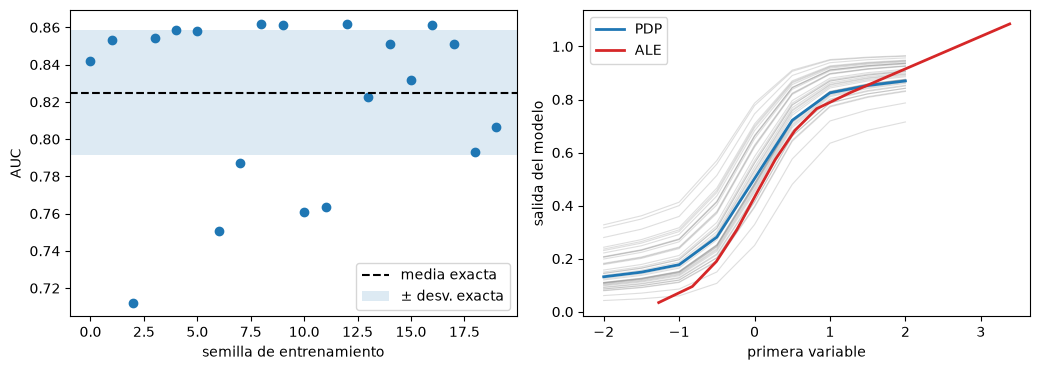

In [10]:
# Izquierda: AUC por semilla contra la media y la dispersión exactas; derecha: ICE, PDP y ALE de la primera variable
plant, data, disp = dispersion["inestable"]
auc_by_seed = [float(disc.disc_auc(plant.train(s)(data["X"]), data["y"]).metric) for s in SEEDS]
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.8))
left.plot(SEEDS, auc_by_seed, "o")
exact = plant.truth()
left.axhline(exact["mean_auc"], color="black", linestyle="--", label="media exacta")
left.axhspan(exact["mean_auc"] - exact["sd_auc_across_seeds"], exact["mean_auc"] + exact["sd_auc_across_seeds"], alpha=0.15, label="± desv. exacta")
left.set_xlabel("semilla de entrenamiento")
left.set_ylabel("AUC")
left.legend()
for curve_i in ice[:40]:
    right.plot(grid, curve_i, color="tab:gray", alpha=0.25, linewidth=0.8)
right.plot(grid, pdp, color="tab:blue", linewidth=2, label="PDP")
right.plot(edges[1:], ale + pdp.mean(), color="tab:red", linewidth=2, label="ALE")
right.set_xlabel("primera variable")
right.set_ylabel("salida del modelo")
right.legend()
fig.tight_layout()
plt.show()

## Resultados

- **Un AUC estable no es un modelo estable.** En la planta inestable el AUC en 20 semillas tiene una media de 0,8221 y una dispersión de 0,04564 (rojo; los valores exactos son 0,8249 y 0,03354, y 20 semillas sobre una muestra de 5.000 filas dan solo una coincidencia aproximada); en la planta estable la dispersión es 0. Los modelos LightGBM y XGBoost versionados tienen una dispersión de 0,00105 y 0,00079, ambas en verde, y sin embargo **el 62,21% y el 56,72% de los deudores cambian de grado** entre al menos dos de las 20 semillas. La planta muestra la misma separación: el 89,18% de los deudores de la planta inestable cambia de grado, el 0% de la estable. Un validador que lea solo la dispersión del AUC aprobaría un modelo cuyos grados dependen de la semilla.
- **El orden de las atribuciones es más estable que las razones.** En la familia logit lineal (coeficientes movidos en 0,15) la tau de Kendall entre los ordenamientos de importancia de dos reajustes promedia 0,7108, con un mínimo de 0,2857. Las cuatro razones principales de un deudor se traslapan en 0,8105 en promedio (percentil 5 de 0,6766) cuando se leen como contribuciones con signo hacia el incumplimiento, y en 0,8019 (percentil 5 de 0,6413) cuando las mismas atribuciones se leen por valor absoluto. En los modelos versionados la tau media es 0,9253 (LightGBM) y 0,9271 (XGBoost), pero el traslape de códigos de razón es 0,7268 y 0,7121: ámbar en ambos, porque un orden global estable no vuelve estables los cuatro primeros de cada deudor.
- **La aditividad es exacta en un modelo lineal y se comprueba, no se supone.** La brecha es 1,776e-15 para las atribuciones exactas (verde) y 1,000e-06 cuando una columna se desplaza en esa cantidad (rojo contra la tolerancia 1e-9): la prueba lee el desplazamiento sin error. En el documento versionado las atribuciones de LightGBM suman el margen con una brecha de 5,329e-15 (verde) y las de XGBoost con una brecha de 1,750e-06 (rojo). El documento no dice por qué, y este cuaderno no afirma una causa.
- **PDP, ICE y ALE cumplen sus identidades.** La PDP es igual a la media de las curvas ICE (a 1e-12), la ALE tiene 11 bordes para 10 tramos y una media ponderada por conteos de 0, y crece con la primera variable como el modelo. Donde las variables están correlacionadas la ALE y la PDP son cantidades distintas, así que un validador que use un explicador para revisar al otro debe decir cuál es cuál.
- **Los dos explicadores concuerdan en las variables principales y menos en todas.** La correlación de rangos del SHAP absoluto medio y el rango de la ALE es 0,9394 en las diez variables principales y 0,5203 en las 20 (ámbar, reconstruida con el motor hasta la luz versionada). `PAY_0` sube el efecto y `LIMIT_BAL` lo baja, ambas con el signo esperado y sin violación de monotonía.

Lo que los resultados no muestran: la familia de modelos logit lineales y las dos plantas son sintéticas y su inestabilidad se elige; los valores de Shapley de un conjunto de árboles los calcula el pipeline con el `shap` fijado, no este cuaderno; y los puntos de corte (0,01 y 0,02; 0,80 y 0,60; 0,70 y 0,40) son convenciones, no umbrales regulatorios.

## Resumen

- Tres cosas deben mantenerse cuando solo cambia la semilla: el AUC, el grado de cada deudor y la explicación; el motor mide la dispersión del AUC (ddof 1), la proporción de deudores cuyo grado cambia y la tau de Kendall de los rangos de atribución.
- Un código de razón es una contribución con signo hacia el incumplimiento en la escala de log-odds; los cuatro primeros se comparan entre reajustes, y una atribución negativa grande nunca es una razón.
- Las atribuciones de Shapley deben sumar la predicción; la revisión lee la mayor brecha contra 1e-9.
- La PDP es la media de las curvas ICE; la ALE acumula diferencias locales, se centra en media cero y es la descripción más segura cuando las variables están correlacionadas.
- Los explicadores se revisan entre sí (rho de Spearman) y contra el signo y la monotonía esperados de un efecto.
- En el barrido de C20 versionado la dispersión del AUC es verde en ambos aprendices mientras más de la mitad de los deudores cambia de grado y los códigos de razón son ámbar, todo horneado con riskvalidation 0.8.1.

**Qué probar después.** El cuaderno 04 pregunta qué puede prometer un modelo sobre la ventana siguiente (conjuntos conformes) y cómo estimar su AUC antes de que maduren los incumplimientos.

## Referencias

- BCE (2025), Guía de modelos internos, los párrafos sobre la aleatoriedad del entrenamiento, el sobreajuste, la explicabilidad y la justificación de la complejidad (43, 59, 60, 62, 64 a 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Lundberg, S. M. y Lee, S.-I. (2017), A unified approach to interpreting model predictions, NeurIPS, arXiv 1705.07874. https://arxiv.org/abs/1705.07874
- Lundberg, S. M. et al. (2020), From local explanations to global understanding with explainable AI for trees, Nature Machine Intelligence 2(1). https://doi.org/10.1038/s42256-019-0138-9
- Friedman, J. H. (2001), Greedy function approximation: a gradient boosting machine, Annals of Statistics 29(5). https://doi.org/10.1214/aos/1013203451
- Goldstein, A., Kapelner, A., Bleich, J. y Pitkin, E. (2015), Peeking inside the black box: visualizing statistical learning with plots of individual conditional expectation, Journal of Computational and Graphical Statistics 24(1). https://doi.org/10.1080/10618600.2014.907095
- Apley, D. W. y Zhu, J. (2020), Visualizing the effects of predictor variables in black box supervised learning models, Journal of the Royal Statistical Society B 82(4). https://doi.org/10.1111/rssb.12377
- EBA (2023), Follow-up report on machine learning for IRB models, EBA/REP/2023/28. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2023/1061483/Follow-up%20report%20on%20machine%20learning%20for%20IRB%20models.pdf
- Yeh, I-C. y Lien, C-H., Default of credit card clients, UCI Machine Learning Repository (CC BY 4.0), las tarjetas de Taiwán de las variantes de C20. https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients